# Insights from Failed Orders

In this notebook, we will investigate metrics for Doordash orders that were not delivered to customers successfully. We will look into cancellations and reasons for order rejection and determine the main causes of order failure. We will also plot the distribution of failed orders, cancellations, and average ETA over time to see if there are temporal factors in play as well. 

## Importing the Data

In [198]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# https://platform.stratascratch.com/data-projects/insights-failed-orders
orders = pd.read_csv('datasets/data_orders.csv')
offers = pd.read_csv('datasets/data_offers.csv')

In [199]:
orders.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0
4,21:24:45,-0.967605,51.458236,NaN,3000583140877,9,0,NaN


In [200]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 10716 entries, 0 to 10715
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_datetime                 10716 non-null  str    
 1   origin_longitude               10716 non-null  float64
 2   origin_latitude                10716 non-null  float64
 3   m_order_eta                    2814 non-null   float64
 4   order_gk                       10716 non-null  int64  
 5   order_status_key               10716 non-null  int64  
 6   is_driver_assigned_key         10716 non-null  int64  
 7   cancellations_time_in_seconds  7307 non-null   float64
dtypes: float64(4), int64(3), str(1)
memory usage: 753.6 KB


In [201]:
offers.head()

,order_gk,offer_id
0,3000579625629,300050936206
1,3000627306450,300052064651
2,3000632920686,300052408812
3,3000632771725,300052393030
4,3000583467642,300051001196


In [202]:
offers.info()

<class 'pandas.DataFrame'>
RangeIndex: 334363 entries, 0 to 334362
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   order_gk  334363 non-null  int64
 1   offer_id  334363 non-null  int64
dtypes: int64(2)
memory usage: 5.1 MB


Both datasets have an order_gk column, so let's use a left merge to append offer_id info to the orders.

In [203]:
df = pd.merge(orders, offers, how='inner', on='order_gk')
df.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,offer_id
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,300050983403
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0,300050986179
2,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0,300050986174
3,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0,300050986180
4,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0,300050976275


## Sources of Failure

In [204]:
print(df['order_status_key'].unique())
print(df['is_driver_assigned_key'].unique())

[4 9]
[1 0]


The orders CSV includes orders with an order_status_key of 4 (cancelled by client) or 9 (cancelled by system). Let's see whether there are more cancellations initated by the client or the system. The is_driver_assigned_key uses boolean 0 and 1 to represent no and yes respectively. Let's change the columns to be more descriptive instead of using numbers.

In [205]:
df['order_status_key'] = df['order_status_key'].replace({4: 'Client', 9: 'System'})
df['is_driver_assigned_key'] = df['is_driver_assigned_key'].replace({0: 'No', 1: 'Yes'})

In [206]:
status_and_driver = df.groupby(['is_driver_assigned_key', 'order_status_key'])['order_datetime'].count().unstack()
status_and_driver

order_status_key,Client,System
is_driver_assigned_key,,
No,13435,9469
Yes,8360,4


The large majority of orders are cancelled before a driver is assigned, suggesting that customers may have cancelled after to waiting too long for a driver assignment. Surprisingly, only 4 orders are cancelled by the system after a driver is assigned.

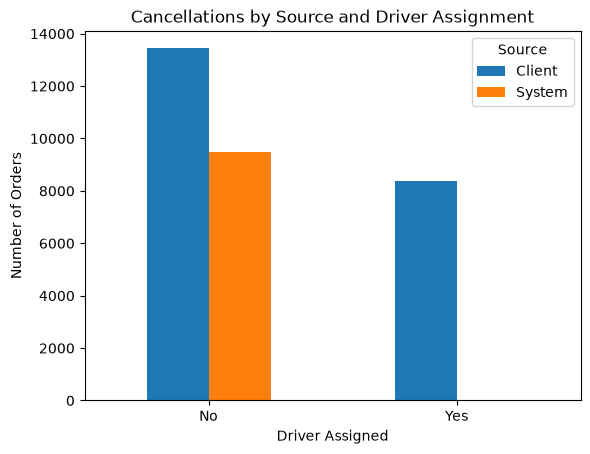

In [207]:
status_and_driver.plot(kind='bar')
plt.xticks(rotation=0)
plt.title('Cancellations by Source and Driver Assignment')
plt.xlabel('Driver Assigned')
plt.ylabel('Number of Orders')
plt.legend(title='Source')

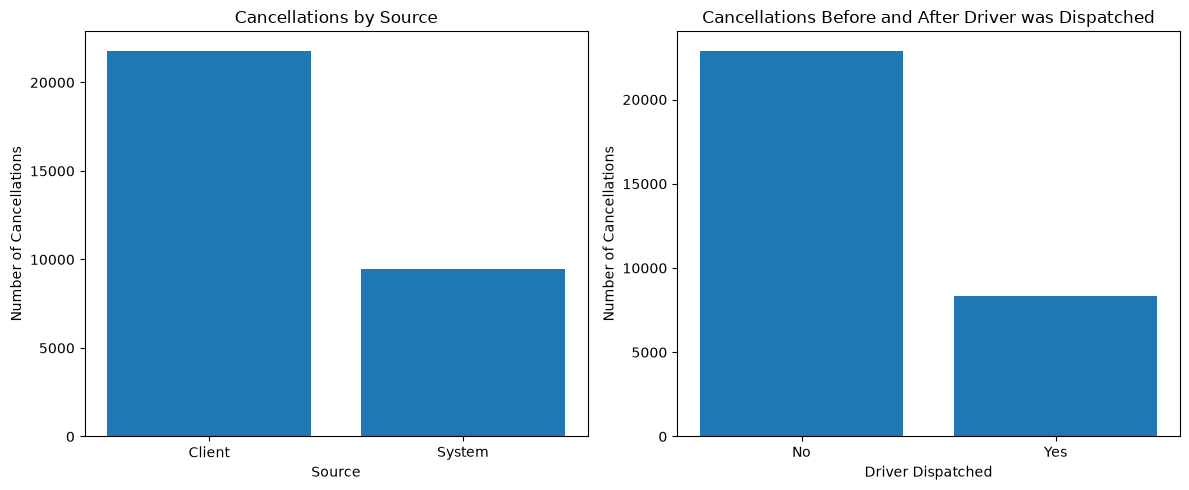

In [208]:
status = df.groupby('order_status_key')['order_datetime'].count()
driver = df.groupby('is_driver_assigned_key')['order_datetime'].count()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].bar(status.index, status.values)
ax[0].set_title('Cancellations by Source')
ax[0].set_xlabel('Source')
ax[0].set_ylabel('Number of Cancellations')

ax[1].bar(driver.index, driver.values)
ax[1].set_title('Cancellations Before and After Driver was Dispatched')
ax[1].set_xlabel('Driver Dispatched')
ax[1].set_ylabel('Number of Cancellations')

fig.tight_layout()

In [209]:
print(status['Client'] / status.sum())
print(driver['No'] / driver.sum())

0.6970385058206473
0.732506076499936


68% of Doordash cancellations originated from the client rather than the system. This reveals that most cancellations are due to the customer's own decision and not Doordash itself.

74% of cancellations occured before the driver was dispatched to pick up the order. This is good because it does not result in any wasted operational expense for the driver (gas, time, wear on the vehicle, etc).

## Temporal Factors

### Cancellations by Time of Day
Let's see what times of the day have the most cancellations.

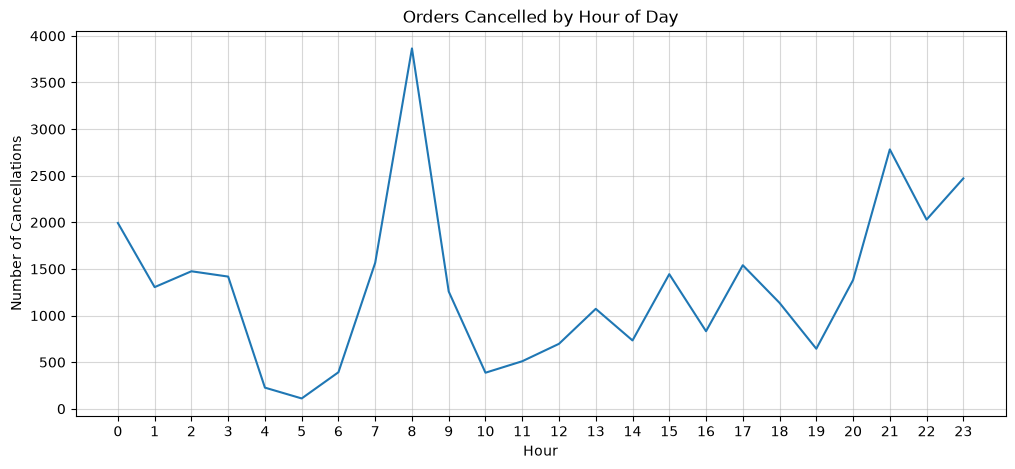

In [230]:
# convert column to datetime and extract hour
df['order_datetime'] = pd.to_datetime(df['order_datetime'], format="%H:%M:%S")
df['order_hour'] = df['order_datetime'].dt.hour
orders_per_hour = df['order_hour'].value_counts().sort_index()

ax= orders_per_hour.plot(figsize=(12,5))
ax.set_title('Orders Cancelled by Hour of Day')
ax.set_xlabel('Hour')
ax.set_xticks(np.arange(0, 24))
ax.set_xticklabels(np.arange(0, 24))
ax.set_ylabel('Number of Cancellations')
ax.grid(alpha=0.5)

The number of orders cancelled spikes significantly at 8am. A potential cause for this is that people order breakfast before work but realize they can't pick it up on time without being late to work. The next highest peaks occur at night around 9pm and 11pm. This may be due to customers getting cravings at night and changing their mind or going to sleep. From the driver's side, they may cancel due to rush hour traffic in the morning or dangerously dark driving conditions at night.

In [231]:
orders_by_hour_split = df.groupby(["order_hour", "is_driver_assigned_key", "order_status_key"])["order_gk"].count()
orders_by_hour_split

order_hour  is_driver_assigned_key  order_status_key
0           No                      Client               957
                                    System               706
            Yes                     Client               326
                                    System                 4
1           No                      Client               633
                                                        ... 
22          No                      System               660
            Yes                     Client               415
23          No                      Client              1144
                                    System               883
            Yes                     Client               444
Name: order_gk, Length: 73, dtype: int64

<Axes: title={'center': 'Count of Failed Orders Per Hour and Category'}, xlabel='order_hour'>

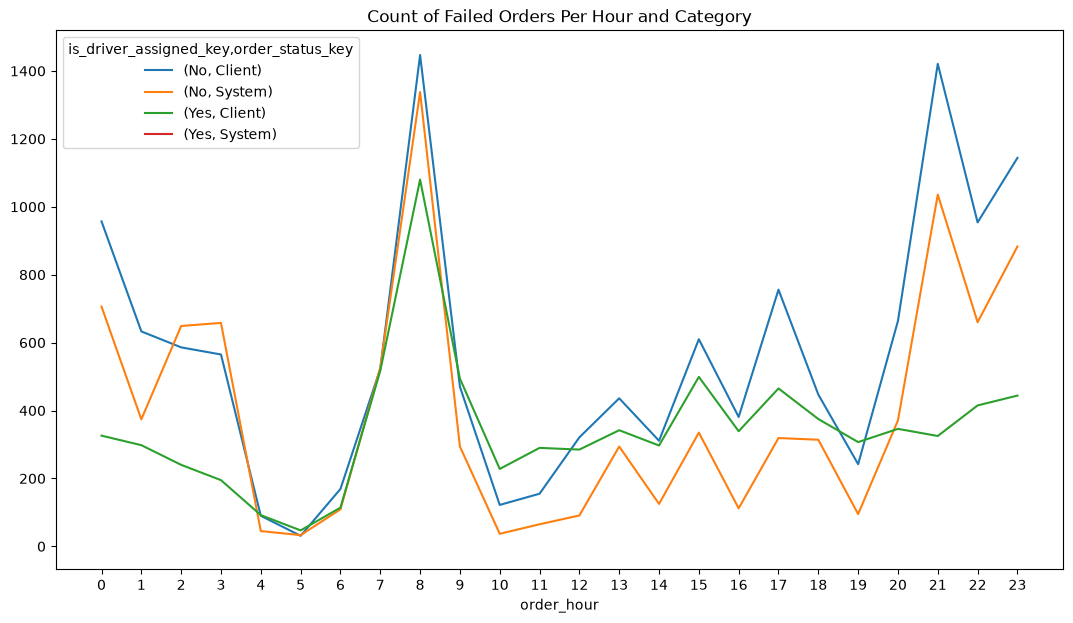

In [247]:
orders_by_hour_split.reset_index().pivot(index='order_hour', 
                                         columns=["is_driver_assigned_key", "order_status_key"],
                                        values='order_gk').plot(xticks=range(0, 24),
                                                               figsize=(13,7),
                                                               title="Count of Failed Orders Per Hour and Category")

All 4 of the orders that were rejected by the system after a driver was assigned occured around midnight. The other categories follow a similar distribution. Orders with an assigned driver had a lower cancellation rate at night.

### Average Time to Cancellations
Let's make a new column converting cancellation times to minutes instead of seconds to make it easier to visualize. We should also remove any outliers in the data.

In [237]:
df['cancellations_in_minutes'] = (df['cancellations_time_in_seconds'] / 60).round(2)

cancellations_with_driver = df[df['is_driver_assigned_key'] == 'Yes']['cancellations_in_minutes'].dropna()
print(cancellations_with_driver.describe())
print(cancellations_with_driver.quantile(0.90)) # remove outliers around > 90th percentile

count    8360.000000
mean        3.897536
std         4.700781
min         0.100000
25%         1.020000
50%         2.050000
75%         4.770000
max        71.720000
Name: cancellations_in_minutes, dtype: float64
10.13


In [238]:
cancellations_without_driver = df[df['is_driver_assigned_key'] == 'No']['cancellations_in_minutes'].dropna()
print(cancellations_without_driver.describe())
print(cancellations_without_driver.quantile(0.90))

count    13435.000000
mean         2.005199
std          1.710892
min          0.050000
25%          0.880000
50%          1.650000
75%          2.800000
max         19.650000
Name: cancellations_in_minutes, dtype: float64
3.77


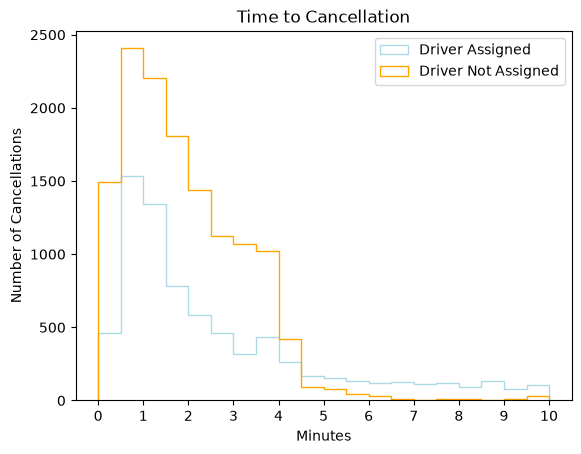

In [239]:
fig, ax = plt.subplots()
ax.hist(cancellations_with_driver, range=(0, 10), bins=20, histtype='step', color='lightblue', label='Driver Assigned')
ax.hist(cancellations_without_driver, range=(0, 10), bins=20, histtype='step', color='orange', label='Driver Not Assigned')
ax.set_title('Time to Cancellation')
ax.set_xlabel('Minutes')
ax.set_xticks(np.arange(0, 11))
ax.set_ylabel('Number of Cancellations')
ax.legend()

In [240]:
df[df['cancellations_in_minutes'] <= 4.5]['cancellations_in_minutes'].count() / df['cancellations_in_minutes'].count()

np.float64(0.8802477632484514)

Almost 90% of cancellations occur within the first 4.5 minutes of an order. After that point, people are much less likely to change their minds. This means that if Doordash wants to take action to prevent cancellations, it must occur during this window of time.

<Axes: title={'center': 'Average Time to Cancellation Per Hour and Driver Assignment'}, xlabel='order_hour'>

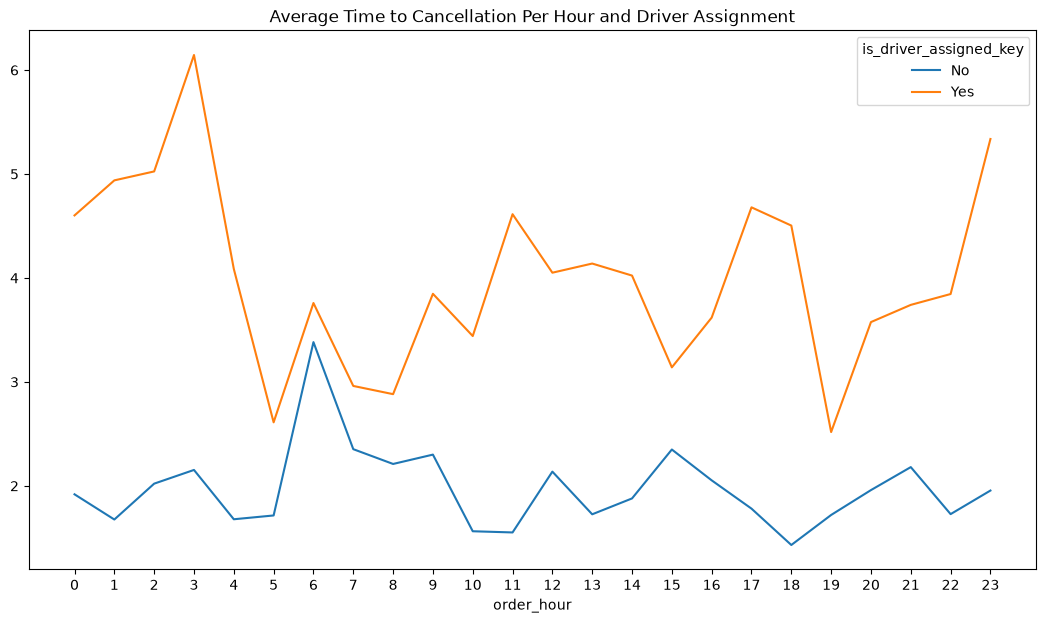

In [248]:
avg_cancel_time = df.groupby(["order_hour", "is_driver_assigned_key"])["cancellations_in_minutes"].mean()
avg_cancel_time.reset_index().pivot(index='order_hour',
                                   columns='is_driver_assigned_key',
                                   values='cancellations_in_minutes').plot(xticks=range(0,24),
                                                                           figsize=(13,7),
                                                                           title="Average Time to Cancellation Per Hour and Driver Assignment")

At every hour of the day, the average time to cancellation is higher for orders with a driver assigned than without. Client cancellations peak at 3am, possibly because it is difficult to get a driver at this time.

### Average Delivery ETA
Although not specifically stated, the ETA also appears to be in seconds. Let's convert it to minutes like we did with the cancellation times and remove any outliers before plotting.

In [249]:
df['eta_in_minutes'] = (df['m_order_eta'].dropna() / 60).round(2)
print(df['eta_in_minutes'].describe())
print(df['eta_in_minutes'].quantile(0.90)) # remove outliers around > 90th percentile

count    8364.000000
mean        7.887536
std         4.751601
min         1.000000
25%         3.970000
50%         6.980000
75%        10.970000
max        23.120000
Name: eta_in_minutes, dtype: float64
14.97


Text(0, 0.5, 'Number of Orders')

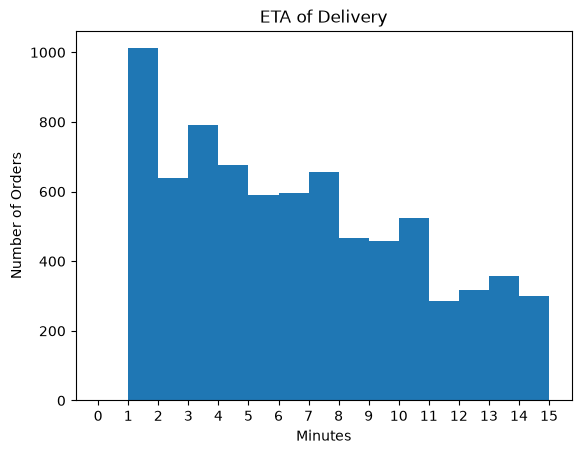

In [250]:
fig, ax = plt.subplots()
ax.hist(df['eta_in_minutes'], range=(0, 15), bins=15)

ax.set_title('ETA of Delivery')
ax.set_xlabel('Minutes')
ax.set_xticks(np.arange(0, 16))
ax.set_ylabel('Number of Orders')

In [251]:
df[df['eta_in_minutes'] <= 8]['eta_in_minutes'].count() / df['eta_in_minutes'].count()

np.float64(0.5948110951697753)

The average delivery time is around 8 minutes. The distribution is right skewed, with 60% of orders estimated to arrive before 8 minutes. There are no estimates less than one minute since the ETA is likely rounded up.

<Axes: title={'center': 'Average ETA per Hour'}, xlabel='order_hour'>

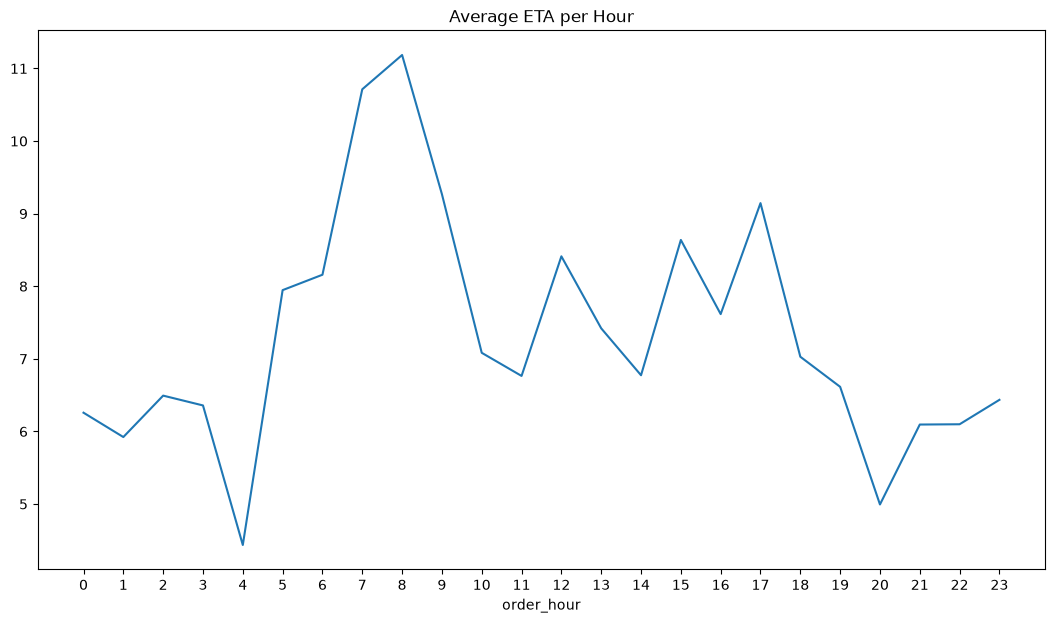

In [253]:
avg_eta = df.groupby("order_hour")["eta_in_minutes"].mean()
avg_eta.plot(xticks=range(0,24), figsize=(13,7), title="Average ETA per Hour")

This graph is similar to the graph of the count of failed orders per hour. This indicates that when customers wait for longer, they are more likely to cancel the order.